# 02 · Models on all provided columns

**Goal:** reproduce the published PhiUSIIL results (≥ 99.9%) with three classical models, using our split (D5).

| Published | Result |
|---|---|
| Prasad & Chandra 2024 (original paper) | 99.79% |
| Bao et al., CMC 2026, Random Forest | 99.99% |

Every model follows the same routine (`src/phishguard/modeling.py`):
1. **Tune** each setting on *train*, score on *validation*, keep the best.
2. **Choose the threshold** on validation.
3. **Test once.** Report the test score and save it to `results/`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

from phishguard.data import load_clean, TARGET
from phishguard.split import get_splits
from phishguard.modeling import param_grid, tune, fit_and_test
from phishguard.evaluate import save_result

df = load_clean()
splits = get_splits(df)
y = df[TARGET]

## Inputs

All numeric columns the dataset provides. The four text columns (`URL`, `Domain`, `TLD`, `Title`) are left out, because these models need numbers.

In [2]:
X = df.drop(columns=TARGET).select_dtypes("number")
print(X.shape[1], "columns:", ", ".join(X.columns))

50 columns: URLLength, DomainLength, IsDomainIP, URLSimilarityIndex, CharContinuationRate, TLDLegitimateProb, URLCharProb, TLDLength, NoOfSubDomain, HasObfuscation, NoOfObfuscatedChar, ObfuscationRatio, NoOfLettersInURL, LetterRatioInURL, NoOfDegitsInURL, DegitRatioInURL, NoOfEqualsInURL, NoOfQMarkInURL, NoOfAmpersandInURL, NoOfOtherSpecialCharsInURL, SpacialCharRatioInURL, IsHTTPS, LineOfCode, LargestLineLength, HasTitle, DomainTitleMatchScore, URLTitleMatchScore, HasFavicon, Robots, IsResponsive, NoOfURLRedirect, NoOfSelfRedirect, HasDescription, NoOfPopup, NoOfiFrame, HasExternalFormSubmit, HasSocialNet, HasSubmitButton, HasHiddenFields, HasPasswordField, Bank, Pay, Crypto, HasCopyrightInfo, NoOfImage, NoOfCSS, NoOfJS, NoOfSelfRef, NoOfEmptyRef, NoOfExternalRef


## 1. Logistic Regression

A linear model: a weighted sum of the columns, passed through a sigmoid. Columns are standardised first (mean 0, standard deviation 1), because the weights are only comparable when the columns are on the same scale. `C` controls regularisation: smaller `C` means simpler weights.

In [3]:
make_logreg = lambda C: make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=2000))
table, best = tune(make_logreg, param_grid(C=[0.01, 0.1, 1.0, 10.0]), X, y, splits)
table

,C,val_accuracy,val_roc_auc
0,1.00,1.000000,1.0
1,10.00,1.000000,1.0
2,0.10,0.999943,1.0
3,0.01,0.999829,1.0


In [4]:
logreg, t, m = fit_and_test(make_logreg(**best), X, y, splits)
save_result("LogReg (all columns)", "all provided columns", t, m)
pd.Series(m).round(5)

accuracy         0.99994
precision        0.99987
recall           1.00000
f1               0.99993
roc_auc          1.00000
tn           20221.00000
fp               2.00000
fn               0.00000
tp           14907.00000
dtype: float64

## 2. Random Forest

Many decision trees, each trained on a random sample of rows and columns. The forest averages their votes. Deeper trees fit more detail; `min_samples_leaf` stops a tree from carving out single rows.

In [5]:
make_rf = lambda max_depth, min_samples_leaf: RandomForestClassifier(
    n_estimators=300, max_depth=max_depth, min_samples_leaf=min_samples_leaf, n_jobs=-1, random_state=42)
table, best = tune(make_rf, param_grid(max_depth=[None, 20], min_samples_leaf=[1, 3]), X, y, splits)
table

,max_depth,min_samples_leaf,val_accuracy,val_roc_auc
0,NaN,1,1.0,1.0
1,NaN,3,1.0,1.0
2,20.0,1,1.0,1.0
3,20.0,3,1.0,1.0


In [6]:
rf, t, m = fit_and_test(make_rf(**best), X, y, splits)
save_result("Random Forest (all columns)", "all provided columns", t, m)
pd.Series(m).round(5)

accuracy         0.99997
precision        0.99993
recall           1.00000
f1               0.99997
roc_auc          1.00000
tn           20222.00000
fp               1.00000
fn               0.00000
tp           14907.00000
dtype: float64

## 3. XGBoost

Gradient boosting: trees are added one at a time, each one correcting the errors of the trees before it. The learning rate scales each tree's contribution down, so more trees (`n_estimators`) are needed but the model generalises better.

In [7]:
make_xgb = lambda max_depth, n_estimators: XGBClassifier(
    max_depth=max_depth, n_estimators=n_estimators, learning_rate=0.1, n_jobs=-1, random_state=42)
table, best = tune(make_xgb, param_grid(max_depth=[4, 6, 8], n_estimators=[200, 500]), X, y, splits)
table

,max_depth,n_estimators,val_accuracy,val_roc_auc
0,4,200,0.999972,1.0
1,4,500,0.999972,1.0
2,6,200,0.999972,1.0
3,6,500,0.999972,1.0
4,8,200,0.999972,1.0
5,8,500,0.999972,1.0


In [8]:
xgb, t, m = fit_and_test(make_xgb(**best), X, y, splits)
save_result("XGBoost (all columns)", "all provided columns", t, m)
pd.Series(m).round(5)

accuracy         1.0
precision        1.0
recall           1.0
f1               1.0
roc_auc          1.0
tn           20223.0
fp               0.0
fn               0.0
tp           14907.0
dtype: float64

## Which columns do the models rely on?

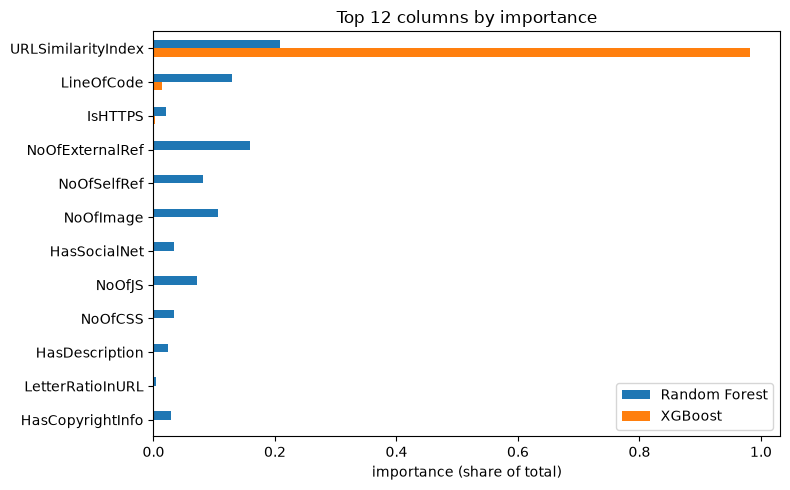

In [9]:
importance = pd.DataFrame({
    "Random Forest": rf.feature_importances_,
    "XGBoost": xgb.feature_importances_,
}, index=X.columns)
top = importance.sort_values("XGBoost", ascending=False).head(12)
top.plot.barh(figsize=(8, 5)).invert_yaxis()
plt.title("Top 12 columns by importance")
plt.xlabel("importance (share of total)")
plt.tight_layout()
plt.show()

## Result

All three models reach the published 99.9%+, and even the simplest one (Logistic Regression) is there.

That's a warning sign as much as a success: when a linear model is nearly perfect, a few columns probably give the label away. The importance chart shows which ones. Several of them (`URLSimilarityIndex`, page-content counts such as `LineOfCode`) are also something a user's typed URL can't provide, so the app can't use them.

→ Notebooks 03 and 04 build models that use **only the URL**. Milestone 3 investigates the dominant columns properly.